# F — Toàn bộ pipeline thực nghiệm NCKH: từ F0 đến nguyên mẫu ESP32-S3

**Bài toán:** phân loại âm thanh hô hấp đã gán nhãn *Asthma / Non-Asthma* qua DSP → Log-Mel → mô hình học sâu → lượng tử hóa INT8 → suy luận tĩnh ESP32-S3 → hiệu chỉnh các điều kiện vận hành.

**Mục đích:** trình bày **tiến trình hình thành quyết định**, không chỉ liệt kê thành tích của cấu hình cuối. Mỗi giai đoạn trả lời ba câu hỏi: *cố định điều gì, thay đổi điều gì, bằng chứng nào cho phép bước tiếp?*

**Phạm vi:** tái tổng hợp các kết quả đã lưu trong A, B0, B, C, D, E và ba notebook hiệu chỉnh vận hành; **không train lại, không chọn lại model, không coi số liệu tĩnh MCU là end-to-end**. Các bảng về Test là *historical Test* đã được dùng/quan sát ở những giai đoạn trước, không phải test độc lập hoàn toàn.

**Kết quả cuối:** `V1 / C4 / seed 44 / QAT INT8` — artifact đã profiling **347.968 B**. Cấu hình vận hành cho nguyên mẫu được trình bày riêng sau khi hoàn tất lập luận chọn model.

## 0. Sơ đồ tiến trình và nguyên tắc lựa chọn

**F0 (DSP giả thuyết)** → **7 kiến trúc trên F0 → chọn V1 tham chiếu** → **B0 kiểm toán nguồn** → **B: OFAT 9 cấu hình/s42** → **B: kiểm tra lỗi WAV + 4×3 seed** → **C: factorial 8×3 → C4/s44** → **D: 72 bản lượng tử + ESP32-S3** → **E: kiểm chứng pre-emphasis và V1/V2/V3** → **Chốt V1/C4/s44/QAT INT8** → **hiệu chỉnh ngưỡng phân loại, Quality Gate, VAD**.

| Vòng | Cố định / đầu vào | Thứ được khảo sát | Bàn giao cho vòng sau |
|---|---|---|---|
| **A — F0** | Tín hiệu 16 kHz / 5 s | Bộ lọc, pre-emphasis, Mel, FFT/hop; mô phỏng đáp ứng | Cấu hình DSP tham chiếu F0 |
| **Phase 2 — Kiến trúc** | **Cùng F0** | 7 implementation V1–V6 (có V4.0/4.1) | **V1 làm kiến trúc thử nghiệm**, không phải thắng Test |
| **B0 — Audit** | Dữ liệu nguồn | Thành phần mẫu, sample rate raw, padding | Cảnh báo confounding trước diễn giải độ chính xác |
| **B — OFAT** | **V1, seed 42, F0** | 9 trial (F0 + 8 biến thể một yếu tố) | Chọn biến pre/Mel/FFT để khảo sát tổ hợp |
| **B — Đối chiếu** | Cùng WAV và/hoặc cùng seed | Paired errors; 4 cấu hình × 3 seed | Thấy rõ rủi ro chọn chỉ từ một seed |
| **C — Factorial** | V1, ba seed 42–44 | 8 tổ hợp pre × Mel × FFT | **C4/s44 FP32** theo Validation |
| **D — Quantization** | 24 checkpoint V1 | PTQ INT8, QAT INT8, PTQ INT16x8; đo board | Bộ ứng viên nhúng, C4 QAT đã profiling |
| **E — Verification** | C4, bằng chứng MCU; đối chứng pre | 7 seed; V2/V3 và latency thực đo | **V1/C4/s44/QAT INT8** |
| **Hiệu chỉnh vận hành** | Model đã khóa | LOW/HIGH, Quality Check, VAD trigger | Tham số nguyên mẫu, **không hồi tố chọn model** |

**Phân biệt ba loại bằng chứng:** *Validation* là cơ sở quyết định trong thí nghiệm; *historical Test* chỉ mô tả điểm số trên bộ Test đã tham khảo; *static MCU profiling* đo `Invoke()` với tensor chuẩn bị trước (không gồm DSP/thu âm).

## 1. Xác lập Front-End F0 — bộ tham số xuất phát (A)

Đầu tiên, nghiên cứu chọn **một cấu hình xử lý âm thanh cố định để làm mốc so sánh**. Đây là giả thuyết kỹ thuật ban đầu, **không phải kết quả tối ưu hóa**.

| Thành phần | F0 ban đầu | Vai trò kỹ thuật |
|---|---|---|
| Dữ liệu | Mono, **16.000 Hz**, **5 s** (80.000 mẫu) | Cố định cửa sổ đầu vào |
| Butterworth band-pass | **100–2000 Hz**, bậc **5** | Hạn chế năng lượng ngoài dải khảo sát |
| Pre-emphasis | **α = 0,97** | Biến đổi cân bằng phổ, cần kiểm định bằng thí nghiệm |
| STFT | Hann, `n_fft=1024`, `hop_length=625` | Biểu diễn thời gian–tần số |
| Mel filterbank | **64 Mel**, 100–2000 Hz, Slaney | Ánh xạ phổ thành đặc trưng Log-Mel |
| Tensor F0 | **64 × 129 × 1** | Định dạng dữ liệu cho mạng |
| Seed vòng thăm dò | **42** | Cố định yếu tố ngẫu nhiên khi so các biến thể OFAT |

**Cơ chế xử lý:** `WAV → resample/mono → band-pass → pre-emphasis → STFT → Mel → log(dB) → normalize theo Train → tensor model`. F0 kế thừa α = 0,97 từ tiền lệ DSP/MFCC để tạo đối chứng; A chỉ mô phỏng cơ chế tác động, chưa xác nhận α cần thiết cho Log-Mel CNN.

Một WAV thật được dùng để minh họa lọc Butterworth; phổ sau lọc tập trung hơn trong dải 100–2000 Hz, nhưng **biên độ RMS suy giảm rõ**. Kết quả này không đủ chứng minh dải lọc là lý tưởng cho mọi mẫu hô hấp.

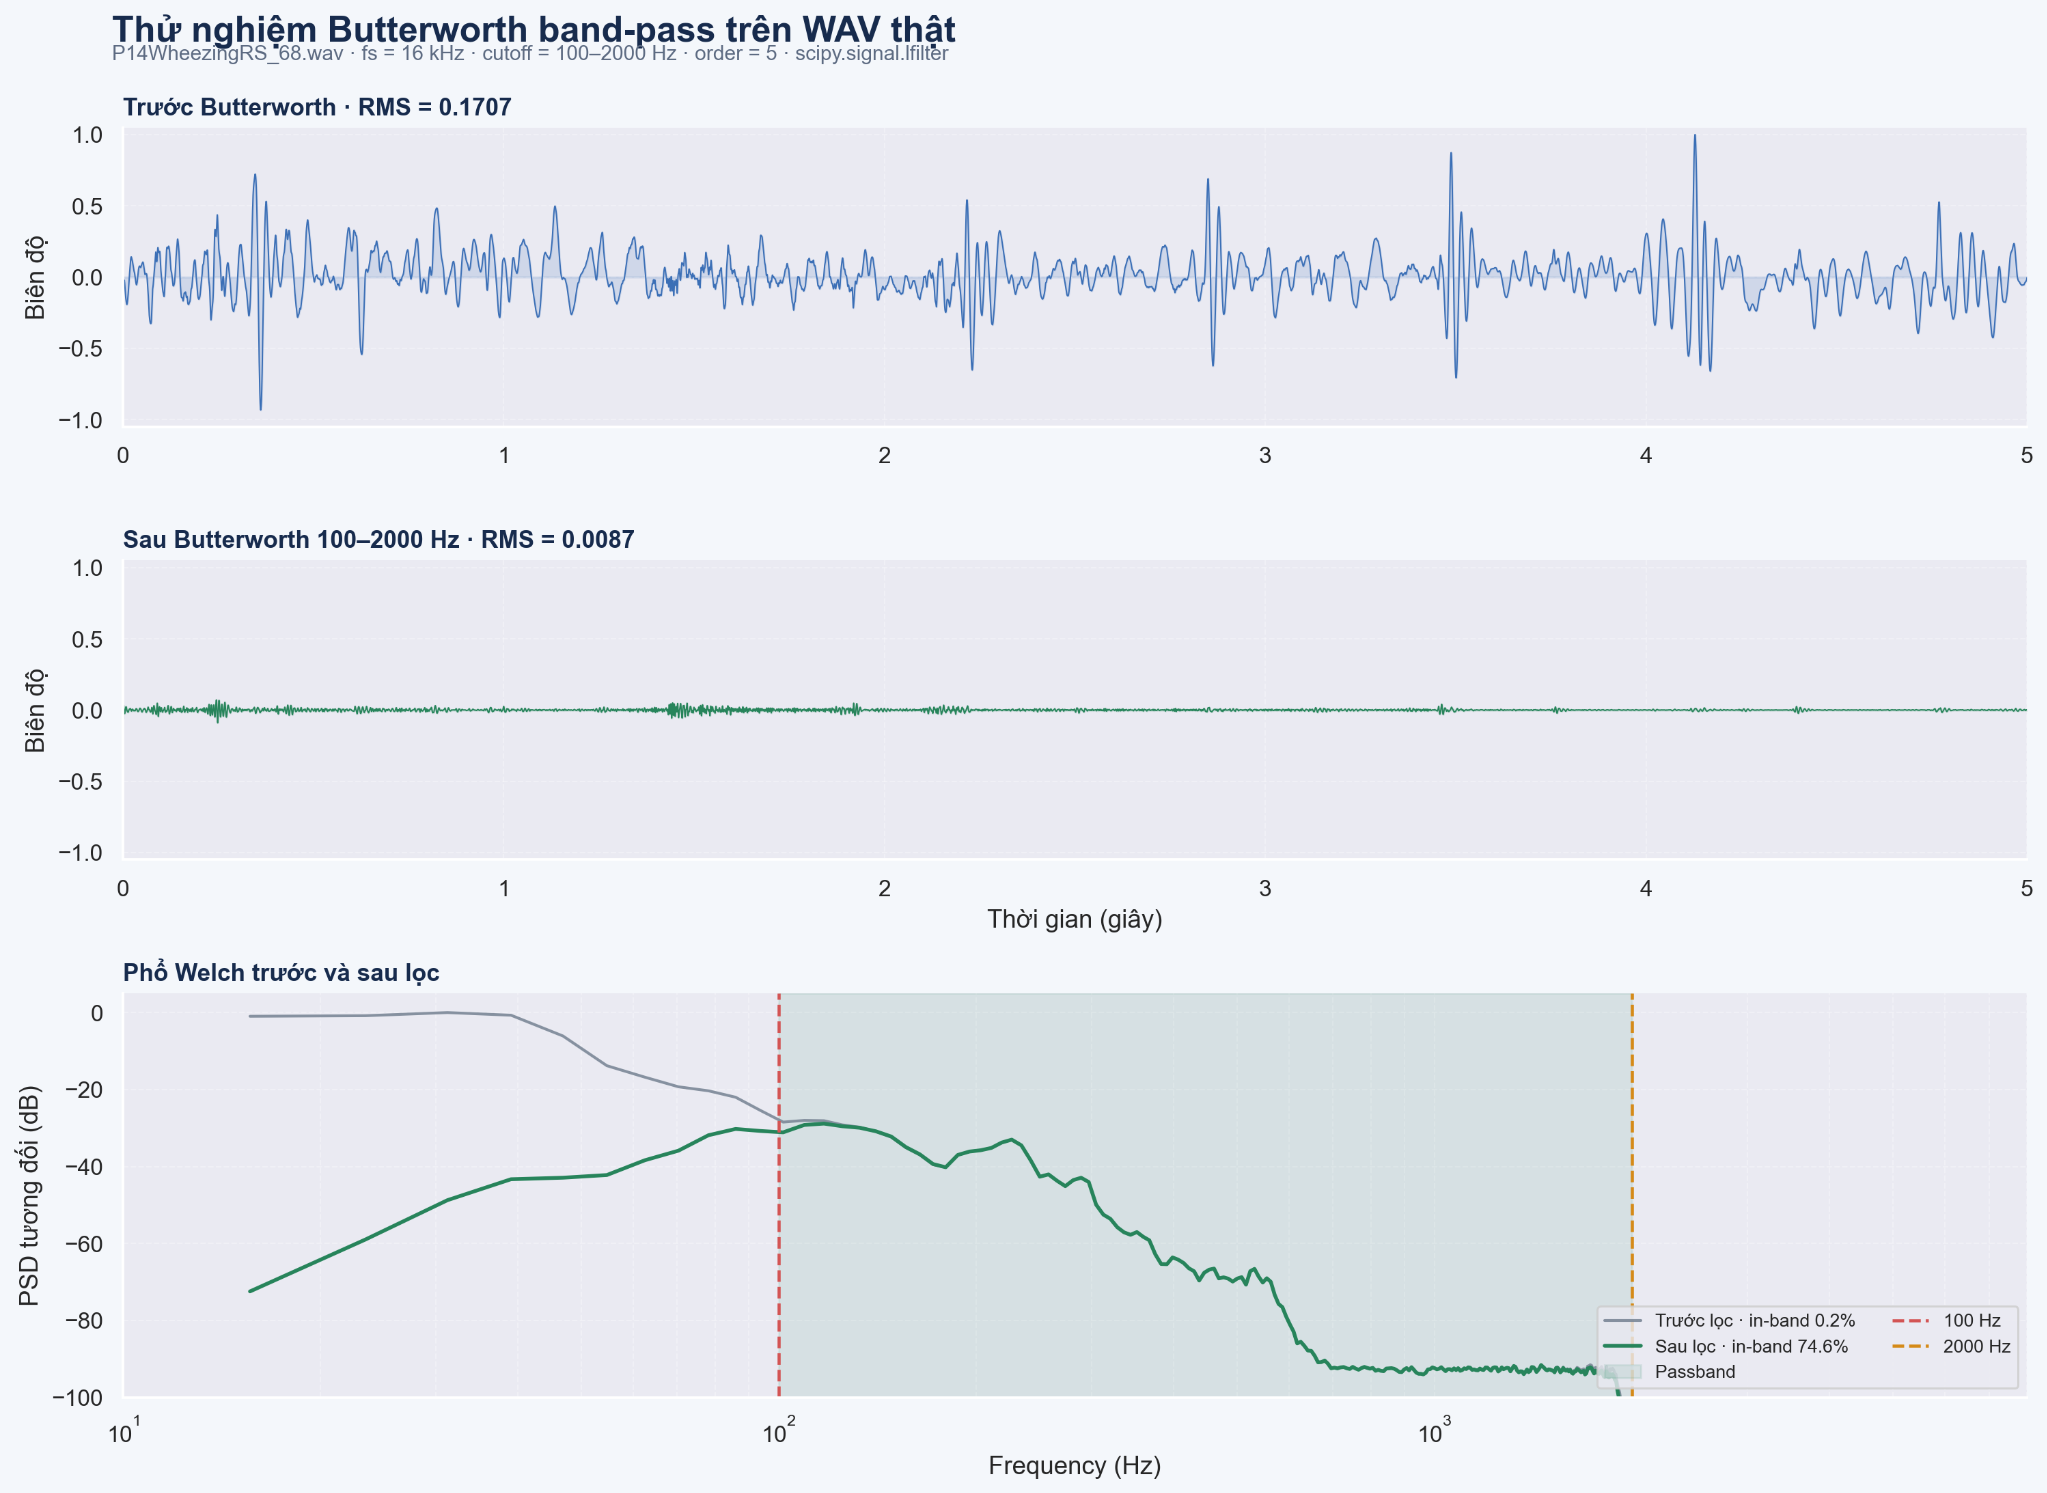

*Hình nguồn A2.1 — P14WheezingRS_68.wav trước/sau Butterworth 100–2000 Hz, bậc 5; chỉ là minh họa trên một WAV. Trên hình RMS giảm từ 0,1707 còn 0,0087; không đồng nghĩa chất lượng phân loại tốt hơn.*

## 2. Từ F0 đến khảo sát kiến trúc — vì sao chọn V1 trước OFAT?

**Bước tiếp theo, vẫn giữ nguyên Front-End F0**, thí nghiệm Phase 2 lịch sử đối chiếu **7 implementation thuộc sáu họ kiến trúc**. Đây là các điểm **Test FP32 lịch sử** từ nguồn A/B; không phải phép benchmarking lại trên C4.

| Kiến trúc trên F0 | Tham số | Test FP32 Accuracy | Đặc điểm |
|---|---:|---:|---|
| **V1 — DS-CNN + Flatten** | **527.994** | **89,31%** | SeparableConv2D; lựa chọn tham chiếu cho nhánh DSP |
| V2 — DS-CNN + GAP | 7.802 | 86,79% | Rất ít tham số |
| V3 — HelloEdge DS-CNN | 23.617 | 86,16% | Thiết kế nhỏ hướng nhúng |
| V4.0 — MobileNetV1-style | 1.371.361 | 86,79% | Nhiều tham số |
| V4.1 — MobileNetV1-style | 480.321 | 79,87% | Chất lượng thấp trong bảng lịch sử |
| **V5 — Standard CNN 3-block** | 548.161 | **91,82%** | Accuracy cao nhất vòng F0 |
| V6 — Separable CNN + GAP | 8.401 | 81,13% | Gọn, nhưng Accuracy lịch sử thấp |

**Điểm quyết định:** V5 đạt Test Accuracy cao nhất (**91,82%**), không phải V1 (**89,31%**). V1 vẫn được **chọn sơ bộ** do kiến trúc separable và mức chất lượng cạnh tranh, phục vụ mục tiêu cố định **cùng một mạng** để so Front-End trong B/C. Quyết định này **không khẳng định V1 nhỏ nhất, nhanh nhất hoặc tối ưu trên ESP32-S3**; điều đó chỉ được kiểm chứng ở D/E.

**Cảnh báo định danh:** `V5 Standard CNN 3-block` trong bảng Phase 2 không mặc nhiên cùng builder với `V5_ERespiNet` ở một số benchmark C4 về sau. Các nhãn V1–V6 cần gắn với version/builder/recipe khi so xuyên giai đoạn.

*Nguồn: A1.1; bảng Phase 2 lịch sử được trình bày ở B0 của notebook `B_F0_Architecture_and_OFAT_Exploration.ipynb`.*

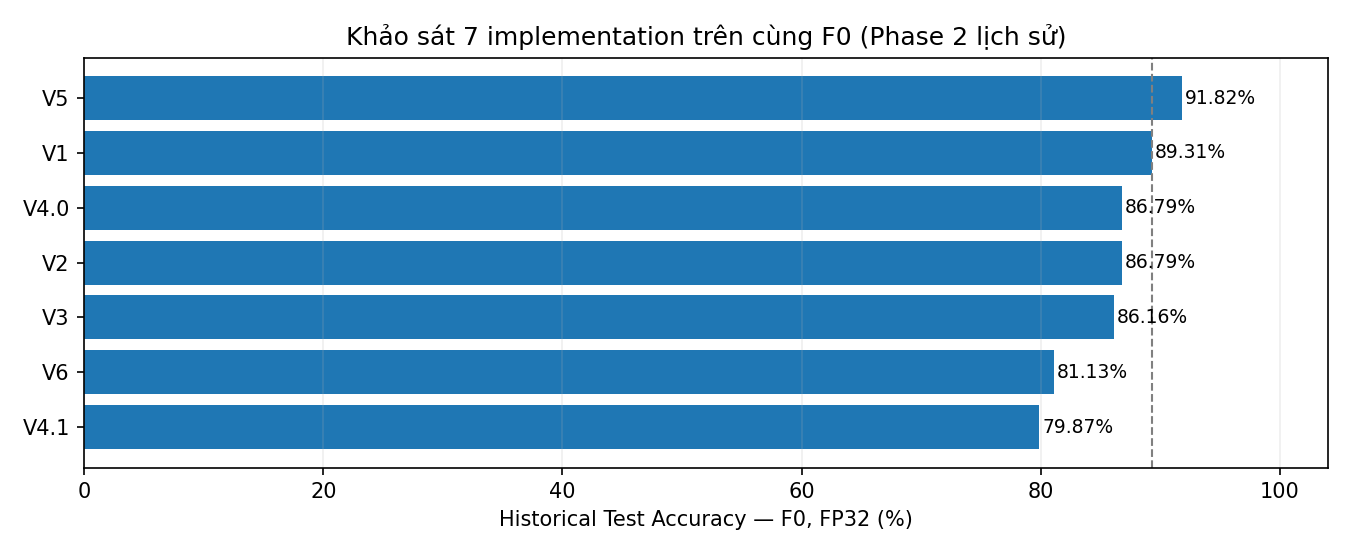

*Hình F2 — V5 đứng đầu Accuracy của bảng lịch sử; V1 được chọn làm mạng tham chiếu cho OFAT vì mục tiêu thiết kế thí nghiệm và hướng triển khai, **không phải vì đứng đầu biểu đồ**.*

## 3. B0 — Kiểm toán dữ liệu trước khi diễn giải kết quả học máy

Sau khi cố định kiến trúc tham chiếu, cần kiểm tra các đặc tính nguồn WAV vì độ chính xác có thể phản ánh **dấu hiệu nguồn ghi** chứ không chỉ tín hiệu hô hấp.

| Split | Asthma | Non-Asthma | Tổng |
|---|---:|---:|---:|
| Train | 987 | 987 | **1.974** |
| Validation | 38 | 116 | **154** |
| Test | 38 | 121 | **159** |

Train được cân bằng theo nhãn nhưng gồm nhiều nguồn: Asthma **228 raw, 64 playback, 695 augmentation**; Non-Asthma **653 raw, 64 playback, 270 environment**.

| WAV **raw** có sample rate gốc 4 kHz | Asthma | Non-Asthma |
|---|---:|---:|
| Train | **205/228 (89,91%)** | 165/653 (25,27%) |
| Validation | **30/30 (100%)** | **1/78 (1,28%)** |
| Test raw (audit header hậu nghiệm) | 27/30 (90%) | 37/83 (44,58%) |

Raw 4 kHz chỉ chứa thông tin đến Nyquist 2 kHz; resample lên 16 kHz **không khôi phục phổ đã mất**. B0 cũng ghi nhận **24/2.287 (1,05%)** trường hợp zero-padding. Đây là các **giới hạn thiết kế dữ liệu**, không phải lý do để tự động loại mẫu khi không có protocol mới.

*B0 là kiểm toán hỗ trợ diễn giải B/C/D/E; không dùng kết quả Test để quyết định tham số Front-End.*

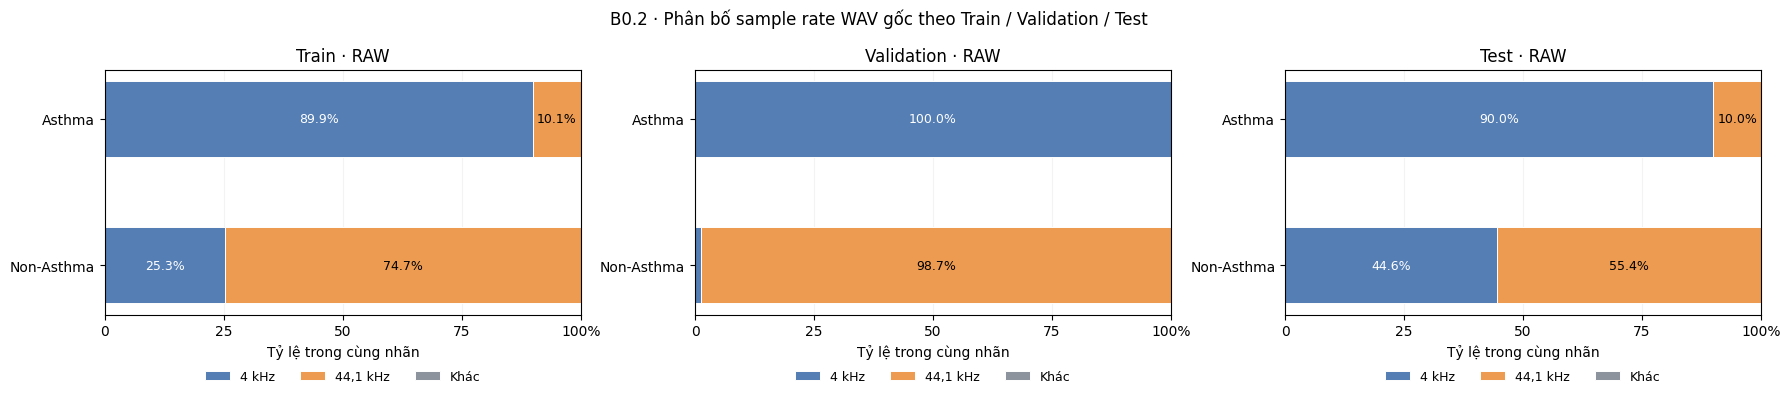

*Biểu đồ được lấy từ output của notebook B0; biểu diễn nhóm WAV raw theo sample rate, không phải phân bố mọi mẫu augmentation.*

## 4. B1 — OFAT 9 cấu hình từ F0/V1/seed 42

**OFAT = One Factor At a Time.** Cố định **kiến trúc V1, seed 42, split và training recipe**; giữ F0 làm mốc rồi thay **một tham số** trong mỗi trial. **8 biến thể + F0 = 9 cấu hình**, tất cả dưới đây là **Validation 154 WAV**, không phải Test.

| Trial | Thành phần được thay so với F0 | Val Accuracy | Δ Accuracy (pp) | Asthma FN | Non-Asthma FP | Tham số V1 |
|---|---|---:|---:|---:|---:|---:|
| **F0** | Không thay | **94,16%** | — | 1 | 8 | 527.994 |
| `order_3` | Butterworth 5 → 3 | 94,81% | +0,65 | 1 | 7 | 527.994 |
| `order_7` | Butterworth 5 → 7 | 94,16% | 0,00 | 2 | 7 | 527.994 |
| `pre_0` | α 0,97 → 0 | **96,10%** | +1,95 | **0** | 6 | 527.994 |
| `pre_095` | α 0,97 → 0,95 | 94,16% | 0,00 | **0** | 9 | 527.994 |
| `mel_40` | Mel 64 → 40 | **98,05%** | **+3,90** | **0** | 3 | 331.386 |
| `mel_80` | Mel 64 → 80 | 94,81% | +0,65 | 3 | 5 | 659.066 |
| `hop_800` | Hop 625 → 800 | 94,16% | 0,00 | 2 | 7 | 396.922 |
| `fft_2048` | FFT 1024 → 2048 | **96,75%** | +2,60 | 2 | 3 | 527.994 |

**Bằng chứng để đi tiếp:** `mel_40`, `pre_0`, `fft_2048` nổi bật về Validation khi xét từng yếu tố; `mel_40` đồng thời giảm số tham số mạng. Nhưng không thể kết luận tổ hợp của ba thay đổi tự động tốt hơn, vì OFAT **không đo tương tác** và chỉ dùng **một seed**.

*Truy vết: B1, snapshot 9 báo cáo Val (seed 42); 1 mẫu Validation tương đương xấp xỉ 0,649 điểm phần trăm.*

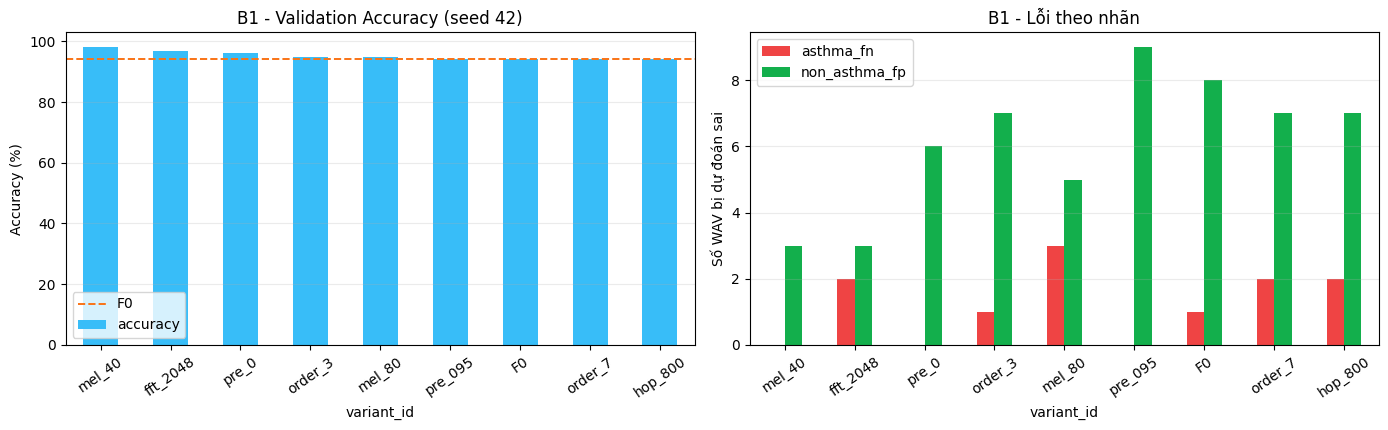

*Hình output B1.3: so sánh OFAT seed 42; những khác biệt chỉ có giá trị thăm dò.*

### 4.1. B2/B3 — Kiểm tra lỗi theo WAV và lặp lại trên nhiều seed

B2 so cùng **154 WAV Validation** tại s42: `mel_40` sửa **6** lỗi F0, tạo **0** lỗi mới; `pre_0` sửa **5**, thêm **2**; `fft_2048` sửa **5**, thêm **1**. Đây là *paired errors*, không phải một lần Test mới.

B3 kiểm tra bốn cấu hình đơn **F0 / Pre0 / Mel40 / FFT2048 × 3 seed (42–44)**:

| Biến thể (vẫn là thay đổi đơn) | Val Accuracy Mean ± SD mẫu (3 seed) |
|---|---:|
| F0 | **97,19 ± 2,93%** |
| Pre0 | **97,19 ± 1,87%** |
| Mel40 | **96,54 ± 1,35%** |
| FFT2048 | **96,97 ± 0,37%** |

**Ý nghĩa:** thứ hạng ở s42 không nhất thiết giữ nguyên khi đổi seed; ngoài độ chính xác phải xem **lỗi từng WAV, độ dao động và tương tác tham số**. B vì vậy **chỉ chuyển ba biến pre, Mel, FFT sang C**, chưa lựa chọn C4/s44.

*Không tráo số B3 này với C: B3 là các thay đổi **đơn**, C mới là các **tổ hợp**.*

## 5. C — Khảo sát tổ hợp factorial 8 Front-End × 3 seed

Từ B, **giữ V1, Butterworth bậc 5/100–2000 Hz, hop 625**, chỉ khảo sát `pre∈{0;0,97} × Mel∈{40;64} × FFT∈{1024;2048}` trên **s42/s43/s44 = 24 checkpoint FP32**.

| Front-End | α | Mel | FFT | Mục đích |
|---|---:|---:|---:|---|
| F0 | 0,97 | 64 | 1024 | Mốc |
| Pre0 | 0 | 64 | 1024 | Tác động tắt pre |
| Mel40 | 0,97 | 40 | 1024 | Tác động giảm Mel |
| FFT2048 | 0,97 | 64 | 2048 | Tác động tăng FFT |
| C1 | 0 | 40 | 1024 | pre OFF + Mel40 |
| C2 | 0 | 64 | 2048 | pre OFF + FFT2048 |
| C3 | 0,97 | 40 | 2048 | **Đối chứng bật pre của C4** |
| **C4** | **0** | **40** | **2048** | **Ứng viên lựa chọn** |

| Nhánh (3 seed) | Val Accuracy Mean ± SD | Diễn giải |
|---|---:|---|
| **C1** | **98,27 ± 1,35%** | Mean nhỉnh hơn nhưng dao động lớn hơn |
| C3 | 97,19 ± 0,99% | Cùng Mel/FFT với C4, bật pre |
| **C4** | **98,05 ± 0,65%** | Chất lượng cao, biến thiên nhỏ hơn hai nhánh trên |

**Quyết định Front-End:** ưu tiên **C4 = pre OFF, Mel40, FFT2048** vì cân bằng Accuracy–SD Validation và quy mô V1 **331.386 tham số** so với **527.994 tại F0** (~37,2% ít hơn), **không nói C4 thắng mọi metric**. Tăng FFT có thể tăng chi phí DSP, chưa có đo end-to-end ở C.

**Quyết định seed:** Validation C4: **s42 97,403% → s43 98,052% → s44 98,701%** ⇒ chọn **s44**. Historical Test C4/s44 FP32 **90,566%**, *thấp hơn* s43 **93,082%**; seed 44 **không được chọn vì Test cao hơn**. Historical Test C4 trung bình ba seed **91,61 ± 1,31%**.

**Bàn giao sang D: `V1/C4/s44 FP32` là checkpoint tham chiếu, chưa phải model QAT cuối.**

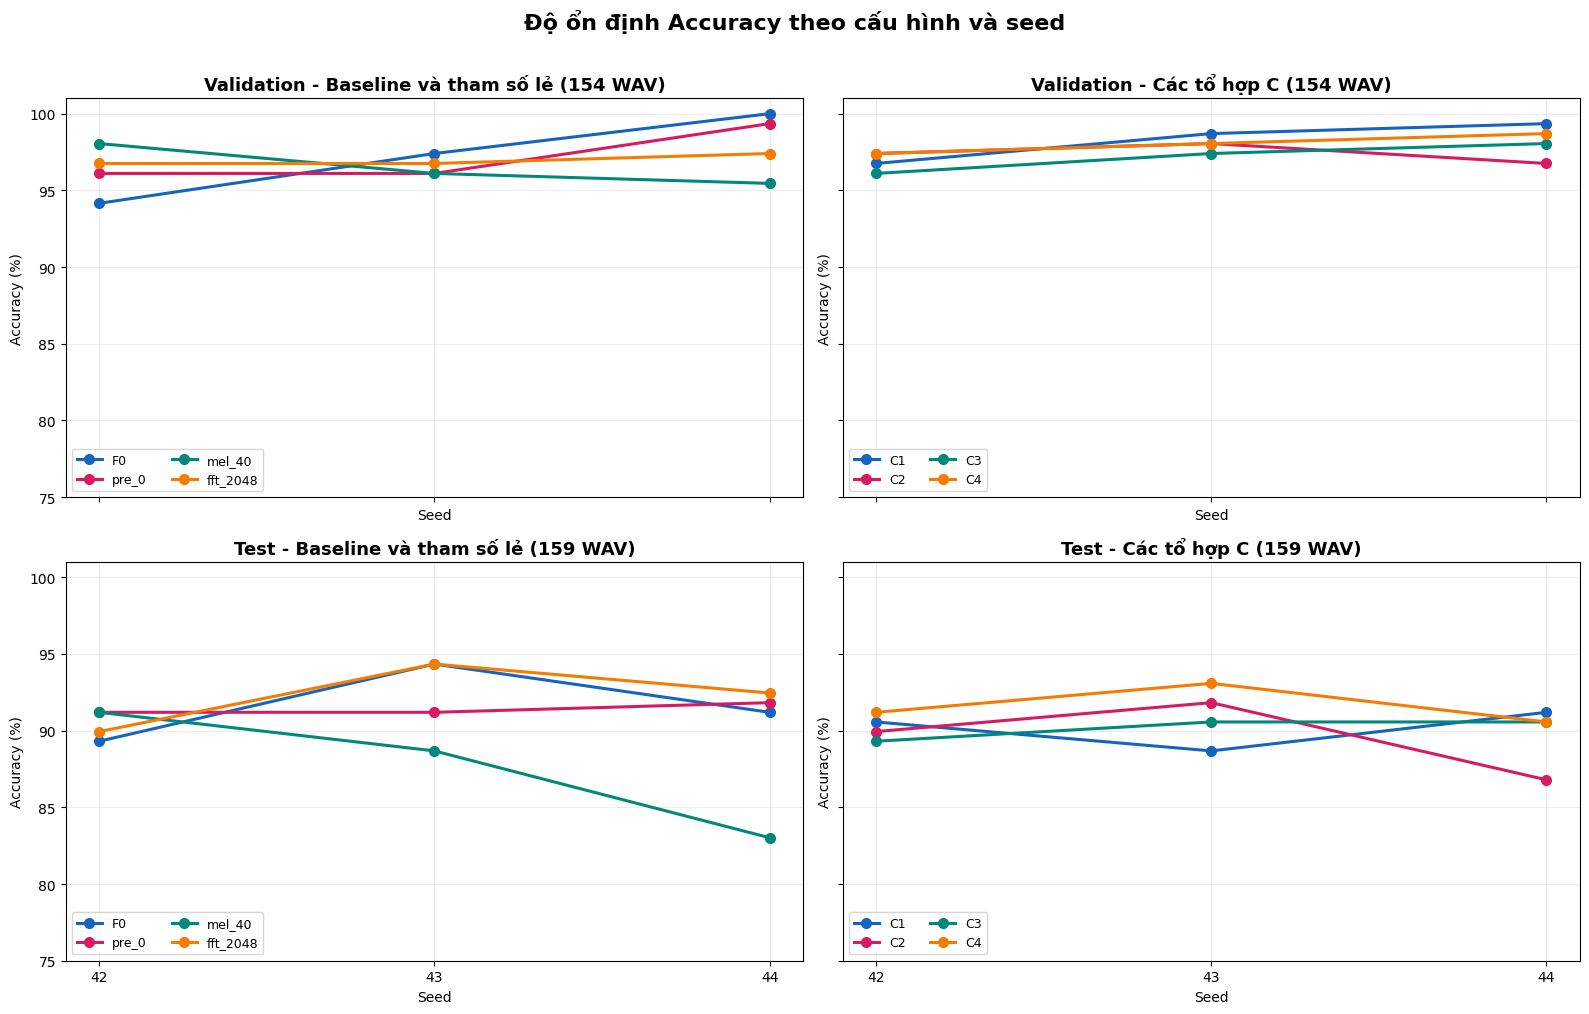

*Hình kết quả trong C5: kết quả theo 3 seed, hữu ích để giải thích trade-off; Test là số liệu lịch sử.*

## 6. D — Từ FP32 sang lượng tử hóa, sau đó kiểm thử ESP32-S3

**24 checkpoint FP32 V1 × 3 phương pháp = 72 artifact lượng tử** (`PTQ_INT8`, `QAT_INT8`, `PTQ_INT16x8`). PTQ INT16x8 chỉ là **mốc phân tích** trong bộ thí nghiệm; chưa được nghiệm thu deploy với cấu hình TFLM ESP32-S3 hiện hành.

| Front-End/QAT INT8 (ba seed) | Val Accuracy Mean ± SD | Historical Test Accuracy Mean ± SD |
|---|---:|---:|
| C1 | **97,62 ± 0,75%** | 90,78 ± 0,96% |
| Pre0 | **97,62 ± 0,99%** | 92,03 ± 0,36% |
| **C4** | 96,97 ± **0,37%** | **93,92 ± 1,58%** |

C1/Pre0 có Validation mean QAT cao hơn C4; C4 có biến thiên Val thấp hơn và Test lịch sử mean cao hơn. **C4 được tiếp tục kiểm thử board**; Test hậu kiểm ở D **không phải cơ sở độc lập để tái chọn cấu hình C**.

| Vai trò log ESP32-S3 | Artifact | Historical Test | Asthma Recall | FN/FP |
|---|---|---:|---:|---:|
| Mốc F0 cho MCU | **F0/s43/PTQ INT8** | 94,340% | 89,474% | 4/5 |
| Đối chứng bật pre | **C3/s44/QAT INT8** | 91,195% | 86,842% | 5/9 |
| **Ứng viên triển khai** | **C4/s44/QAT INT8** | **95,597%** | **92,105%** | **3/4** |

**Lưu ý dòng thời gian:** F0/s42 là mốc **thiết kế OFAT**; F0/s43/PTQ được lấy **hậu kiểm** làm đối chứng board do có Historical Test cao nhất trong nhóm F0/PTQ s42–44. Không đổi tên nó thành baseline khởi đầu. **C4/s44 FP32 Test 90,566% và C4/s44/QAT INT8 Test 95,597% thuộc hai artifact khác nhau.**

### 6.1. Số đo trên ESP32-S3 (ba log chạy tensor tĩnh)

**Điều kiện:** ESP32-S3 **240 MHz**, TensorArena **capacity 1.048.576 B (1 MiB PSRAM)**; `Arena used` là số byte sử dụng, không phải capacity. `Invoke()` chưa gồm microphone, Butterworth, STFT, Mel hoặc thời gian chuẩn bị input.

| Chỉ số | F0/s43 PTQ | C3/s44 QAT | **C4/s44 QAT** |
|---|---:|---:|---:|
| Model `.tflite` (B) | 543.976 | 347.968 | **347.968** |
| Input tensor (B) | 8.256 | 5.160 | **5.160** |
| TensorArena **used** (B) | 268.772 | 169.380 | **169.380** |
| Invoke mean (ms) | 1.869,175 | 1.164,108 | **1.164,203** |
| `Invoke` pass | 36/36 | 36/36 | **36/36** |
| Python↔ESP nhãn | 12/12 | 12/12 | **12/12** |
| Raw INT8 khớp tuyệt đối | 6/12 | 7/12 | **11/12** |
| Max raw difference (LSB) | 26 | 6 | **61** |

So F0/s43/PTQ, C4/s44/QAT giảm **~36,0% file model; ~37,0% Arena used; ~37,7% Invoke mean**. C3 và C4 Invoke gần bằng nhau: **không được suy ra tắt pre giúp kernel Invoke chạy nhanh hơn**, vì pre-emphasis nằm ở DSP bên ngoài mạng.

*Bằng chứng đo: log D14, không phải benchmark end-to-end.*

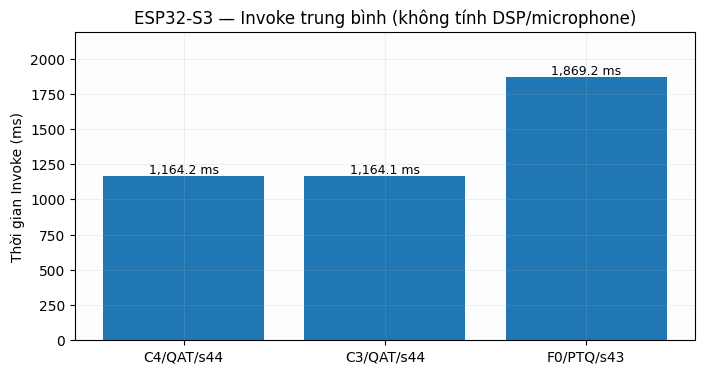

*Biểu đồ D14 từ log static profiling, không tính thu âm/DSP.*

## 7. E — Kiểm chứng trước khi quyết định kiến trúc triển khai

### 7.1. Pre-emphasis trên 7 seed (F0 ↔ Pre0, FP32)

Giữ **V1, Mel64, FFT1024**, so α=0,97 và α=0 ở cùng **7 seed 40–46** (không thay nhiều yếu tố cùng lúc):

| Chỉ số Test FP32 | F0 | **Pre0** |
|---|---:|---:|
| Accuracy Mean ± SD mẫu | 90,566 ± 1,955% | **91,105 ± 0,672%** |
| Macro F1 Mean ± SD mẫu | 87,849 ± 2,417% | **88,475 ± 0,660%** |
| Asthma Recall Mean | 90,226% | 90,602% |

Trong **bảy seed đã đo**, nhánh Pre0 có biến thiên Accuracy nhỏ hơn và mean hơi cao hơn. Đây là bằng chứng mô tả **độ nhạy seed trên dataset hiện có**, không chứng minh α=0 bền vững với nguồn thu/bệnh nhân mới. **Pre0 ≠ C4**: C4 còn thay Mel64→40 và FFT1024→2048.

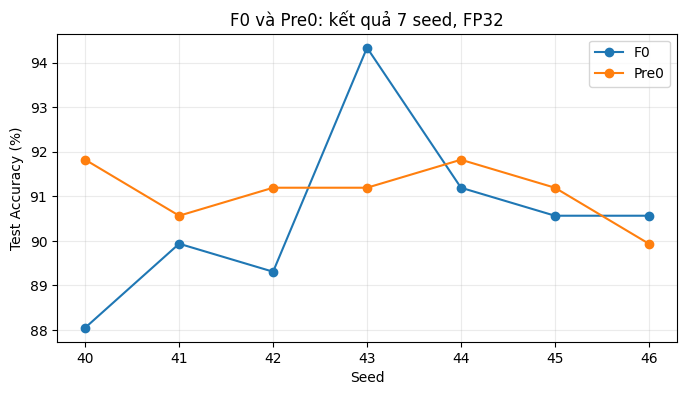

*Hình E2: Test FP32 Accuracy qua seed 40–46; kết quả về biến thiên seed, không phải khả năng tổng quát hóa ngoài dataset.*

### 7.2. Kiểm chứng V2 và V3 trên Front-End C4

Khi đã có C4, cần xem giả định kiến trúc V1 còn phù hợp trên thiết bị hay không:

- **V2/C4/s44 FP32:** 7.802 tham số; Historical Test **91,824%**, so với V1/C4/s44 FP32 **90,566%** (V1 có **331.386** tham số). V2/QAT INT8 lịch sử Test **91,195%**, nhưng **chưa có profiling board** tương ứng.
- **V3 HelloEdge/C4/PTQ INT8:** model file chỉ **47.448 B**, đáng thử như phương án cực gọn, nhưng thời gian MCU cần đo thay vì suy từ số tham số.

| Static board / historical Test | **V1/C4/s44/QAT INT8** | V3/C4/PTQ INT8 |
|---|---:|---:|
| Historical Test Accuracy | **95,597% (152/159)** | 93,711% (149/159) |
| Asthma Recall | 92,105% | 92,105% |
| FN / FP | **3 / 4** | 3 / 7 |
| Model file (B) | 347.968 | **47.448** |
| TensorArena used (B) | **169.380** | 173.188 |
| `Invoke()` mean (ms) | **1.164,203** | 11.452,180 |
| Invoke pass | 36/36 | 36/36 |
| Nhãn Python↔ESP | 12/12 | 12/12 |
| Raw INT8 exact | 11/12 | **12/12** |

V3 nhỏ hơn **~86,4% file model** nhưng **Invoke chậm ~9,84×** trong phép đo này; V1 được ưu tiên cho nguyên mẫu ở điều kiện ESP32-S3 đã thử. Hai artifact còn khác **phương pháp lượng tử (QAT so PTQ)**, do đó phép so không cô lập tác động riêng của kiến trúc.

**Bàn giao cuối vòng chọn model: V1 / C4 / s44 / QAT INT8 (bản 347.968 B).**

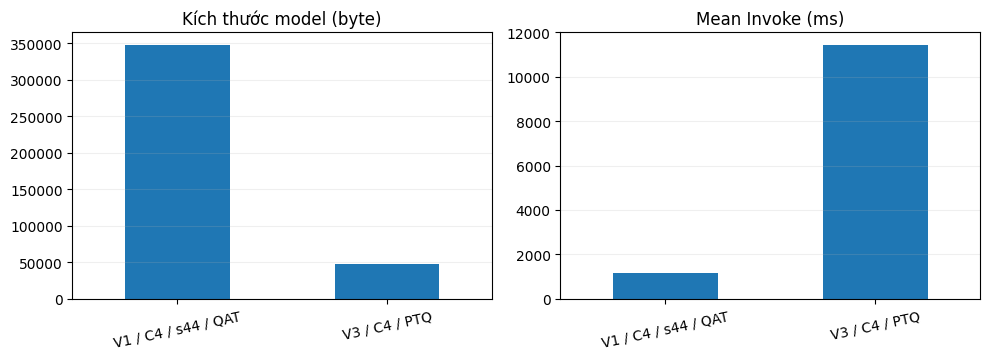

*Hình E4c: so sánh chi phí hai artifact triển khai, không gồm DSP/capture.*

## 8. Từ model đã chốt đến pipeline vận hành Patient Node (giai đoạn sau A–E)

Đây là **hiệu chỉnh hậu xử lý/tín hiệu của nguyên mẫu sau khi đã chọn model**, không phải dữ liệu hồi tố để biện minh việc lựa chọn Front-End hoặc kiến trúc ở A–E.

| Khối vận hành | Tham số nghiên cứu đã chọn | Bằng chứng/giới hạn |
|---|---|---|
| **01 — Classification Threshold** | `p_non_asthma ≤ 0,47` → ASTHMA; `(0,47;0,77)` → UNSURE; `≥ 0,77` → NON_ASTHMA | Validation **146 đúng, 3 sai, 5 UNSURE / 154**; historical Test **147 đúng, 6 sai, 6 UNSURE / 159**; Test có **3 Asthma → Non-Asthma** |
| **02 — Quality Gate** | `min_rms=20`; `block_mav>20`; `active_ratio≥1%`; `clipped_ratio≤1%`; `clip_level=32000`; `block_size=256` | Calibration **207/208** AUDIO_OK; held-out Test lịch sử **21/22** AUDIO_OK; Silence cũ vẫn **60/60 AUDIO_OK** (không phải detector hô hấp) |
| **03 — VAD Trigger** | **MAV >75** trong **4 chunk** 256 mẫu; xác nhận nominal **64 ms**; warmup 100 chunk; ring 1 s; capture 5 s | Playback trigger **119/144 Calibration**, **14/16 Test**; Silence cũ vẫn tạo **15 trigger/300 s**; chưa đo onset âm học thực |

**Thứ tự tích hợp vận hành (phụ thuộc firmware thực tế):** `I2S PCM16 → VAD trigger/capture → Quality Gate → DSP C4 → TFLM V1/QAT → phân loại ba vùng`; trường hợp bấm kiểm tra thủ công có thể bỏ qua bước kích hoạt VAD nhưng không bỏ qua kiểm tra chất lượng. **Cần đối chiếu dữ liệu Python ↔ ESP**, đặc biệt raw INT8 sai khác 1/12 tensor trong phép profiling, trước khi xem đây là pipeline end-to-end đã nghiệm thu.

*Truy vết: `Threshold_Selection`, `Quality_Gate_Selection_V1_Final_Concise`, `VAD_Trigger_Selection_V1_Compact`. Các kết quả này không phải nghiên cứu độc lập trên bệnh nhân mới.*

## 9. Hồ sơ tham số bàn giao cho bản mẫu ESP32-S3

| Nhóm | Giá trị bàn giao |
|---|---|
| Model | **V1 — SeparableConv2D + Flatten** |
| Front-End | **C4:** pre-emphasis **OFF (α=0)**; Mel **40**; FFT **2048** |
| DSP cố định | Mono **16 kHz**, cửa sổ **5 s**; Butterworth **100–2000 Hz, bậc 5**; hop **625** |
| Tensor đầu vào | **40 × 129 × 1**, log-Mel chuẩn hóa bằng min/max Train của đúng conversion metadata |
| Checkpoint | **Seed 44**, QAT **Full INT8** |
| Artifact đúng bản profiling | `.tflite` **347.968 B**; model SHA/recipe phải kiểm tra trong repo khi tích hợp |
| MCU static profiling | Arena used **169.380 B**; Invoke mean **1.164,203 ms** @ 240 MHz; capacity 1 MiB PSRAM |
| Historical Test QAT | **95,597% = 152/159**; Asthma Recall **92,105%**, FN/FP **3/4** |
| Python↔ESP | Invoke 36/36; nhãn 12/12; raw INT8 exact **11/12** |
| Hậu xử lý | LOW/HIGH **0,47/0,77** (có vùng **UNSURE**); Quality Gate/VAD riêng theo mục 8 |

**Cảnh báo phiên bản:** đã có artifact V1/QAT khác cỡ **347.960 B** và Historical Test **93,082%**. **Không đồng nhất** bản này với model **347.968 B / 95,597%**; kiểm tra file, SHA-256, normalization và metadata khi đưa vào firmware.

Kết luận nghiên cứu: **V1/C4/s44/QAT INT8 được chọn trong phạm vi dữ liệu, recipe và phần cứng đã thử**, không tuyên bố tối ưu tuyệt đối hoặc đạt khả năng chẩn đoán bệnh lý.

## 10. Giới hạn và những điều chưa được phép kết luận

1. **Confounding nguồn dữ liệu:** tỷ lệ WAV raw gốc 4 kHz khác mạnh giữa nhãn Asthma và Non-Asthma; Accuracy có thể chịu ảnh hưởng của kênh ghi và nguồn thu.
2. **Historical Test đã được tham khảo:** Test không còn hoàn toàn độc lập đối với toàn bộ chuỗi quyết định; tránh tuyên bố tổng quát hóa ngoài tập dữ liệu từ các điểm cao nhất.
3. **Seed ≠ domain robustness:** độ lệch chuẩn của 3 hoặc 7 seed chỉ mô tả biến thiên trong thí nghiệm hiện có.
4. **Tĩnh ≠ end-to-end:** `Invoke()` không tính thời gian từ microphone, VAD, thu 5 s, DSP, UI hoặc truyền thông; TensorArena used không phải PSRAM tổng thể.
5. **Parity số học cần hoàn thiện:** 12/12 nhãn khớp nhưng có 1/12 raw INT8 khác nhau tới 61 LSB; vùng UNSURE có thể làm lộ sai khác nhãn ba trạng thái.
6. **Quality/VAD không nhận diện nội dung bệnh:** Quality Gate đo mức tín hiệu/chất lượng sơ bộ; VAD dựa năng lượng có thể kích hoạt với tiếng ồn và vẫn có Playback không kích hoạt.
7. **Không phải đánh giá lâm sàng:** hai nhãn dữ liệu là kết quả phân loại nghiên cứu, không phải chẩn đoán hay loại trừ hen suyễn.

**Việc triển khai tiếp:** đối chiếu checksum `.tflite`, xây dựng và kiểm tra DSP cố định-point, đo parity ba vùng, thử microphone I2S/loa và tính thời gian toàn chuỗi trên ESP32-S3. Không đổi ngưỡng/architecture dựa vào Test đã mở mà không có protocol đánh giá mới.

## 11. Nguồn truy vết và bảng kiểm số học

| Nguồn | Nội dung dùng trong F |
|---|---|
| [A — Baseline DSP](../01_Baseline_DSP/A_F0_s42_Baseline_DSP_Foundation.ipynb) | Tham số F0; đáp ứng DSP; bảng kiến trúc Phase 2 lịch sử |
| [B0 — Dataset Audit](../02_Dataset_Audit/B0_SampleRate_Source_Audit.ipynb) | Nguồn WAV, sample rate trước resample, padding |
| [B — OFAT](../03_OFAT_Exploration/B_F0_OFAT_9Trials_Conclusion_Revised.ipynb) | 9 trial/s42, paired errors, 4×3 seed |
| [C — Factorial](../04_Frontend_Selection/C_Factorial_8x3_C4_Selection.ipynb) | 8×3, chọn C4/s44 bằng Validation |
| [D — Quantization/MCU](../05_Quantization_Deployment/D_Quantization_ESP32S3_ThreeLogs_Final.ipynb) | 72 artifact, log F0/C3/C4 |
| [E — Final Verification](../06_Final_Verification/E_Final_Verification_and_Model_Selection.ipynb) | 7 seed; V1/V2/V3, log C4/V3 |
| Patient Node 01/02/03 | Các notebook Threshold, Quality Gate, VAD Trigger của nhánh Final_V1_Validation (lưu riêng, không có trong bộ A–F gốc) |

**Code dưới chỉ tái tính các tỷ lệ từ snapshot đã ghi trong nguồn; không gọi dataset/TensorFlow hoặc giả lập một phép đo MCU mới.**

In [1]:
import statistics
# Số dự đoán đúng trên historical Test 159 WAV; đối chiếu E2/E4c.
f0_correct = [140, 143, 142, 150, 145, 144, 144]       # seeds 40...46
pre0_correct = [146, 144, 145, 145, 146, 145, 143]    # seeds 40...46
f0_pct = [100*x/159 for x in f0_correct]
pre0_pct = [100*x/159 for x in pre0_correct]
for title, x in [('F0 FP32', f0_pct), ('Pre0 FP32', pre0_pct)]:
    print(f'{title:11s} | mean={statistics.mean(x):.3f}% | sample SD={statistics.stdev(x):.3f} pp')
print('---')
print('C4 QAT Test =',f'{100*152/159:.3f}%', '| V3 PTQ Test =', f'{100*149/159:.3f}%')
print('V3 / V1 Invoke =', f'{11452.180/1164.203:.2f}x')
print('V1 C4 param reduction vs F0 =',f'{100*(527994-331386)/527994:.2f}%')
print('C4 vs F0 arena used saving =',f'{100*(268772-169380)/268772:.2f}%')


F0 FP32     | mean=90.566% | sample SD=1.955 pp
Pre0 FP32   | mean=91.105% | sample SD=0.672 pp
---
C4 QAT Test = 95.597% | V3 PTQ Test = 93.711%
V3 / V1 Invoke = 9.84x
V1 C4 param reduction vs F0 = 37.24%
C4 vs F0 arena used saving = 36.98%


In [2]:
# Kiểm tra các con số chính trong pipeline (không train/inference lại)
ofat_correct = {"F0":145,"order_3":146,"order_7":145,"pre_0":148,"pre_095":145,"mel_40":151,"mel_80":146,"hop_800":145,"fft_2048":149}
assert len(ofat_correct)==9
assert all(0 <= n <= 154 for n in ofat_correct.values())
assert round(100*ofat_correct['mel_40']/154,2)==98.05
assert 146+3+5==154 and 147+6+6==159  # Classification Threshold
assert 207+1==208 and 21+1==22        # Quality Gate
assert 119 <= 144 and 14 <= 16        # VAD Playback trigger
assert 152+3+4 == 159                 # C4 QAT historical Test
print('Kiểm tra nhanh: 9 OFAT; Threshold; Quality; VAD; QAT Test — PASS')

Kiểm tra nhanh: 9 OFAT; Threshold; Quality; VAD; QAT Test — PASS
